<a href="https://colab.research.google.com/github/dilipghanchi068-create/clinai-report-analyzer/blob/main/Data_science_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip install scikit-learn

Dataset shape: (67, 2)
category
radiology            19
laboratory           18
discharge_summary    15
consultation         15
Name: count, dtype: int64

Model training completed!
Training samples: 50
Testing samples: 17
Test accuracy: 100.00%

Classification Report:
                   precision    recall  f1-score   support

     consultation       1.00      1.00      1.00         4
discharge_summary       1.00      1.00      1.00         4
       laboratory       1.00      1.00      1.00         4
        radiology       1.00      1.00      1.00         5

         accuracy                           1.00        17
        macro avg       1.00      1.00      1.00        17
     weighted avg       1.00      1.00      1.00        17



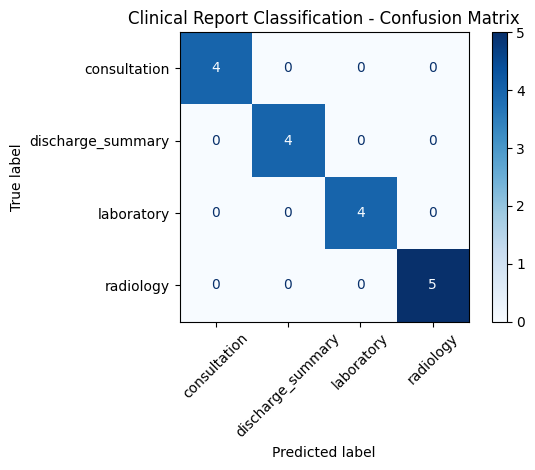

Model saved and loaded successfully!


In [9]:
!pip -q install gradio scikit-learn pandas numpy matplotlib seaborn spacy joblib

import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

random.seed(42)
np.random.seed(42)

reports = [
    ("laboratory", "Blood test report shows hemoglobin and white blood cell counts."),
    ("laboratory", "Laboratory results include glucose, cholesterol and triglyceride measurements."),
    ("laboratory", "The patient's blood sample was analyzed for complete blood count."),
    ("laboratory", "Biochemistry report contains liver function and kidney function results."),
    ("laboratory", "The laboratory report lists creatinine, urea and electrolyte measurements."),

    ("radiology", "Chest X-ray report describes the appearance of the lungs and heart."),
    ("radiology", "MRI report describes findings observed in the brain images."),
    ("radiology", "CT scan report documents imaging findings in the abdominal region."),
    ("radiology", "Radiology findings describe the bones and surrounding soft tissues."),
    ("radiology", "Ultrasound report documents observations of abdominal organs."),

    ("discharge_summary", "The patient was discharged following inpatient treatment and observation."),
    ("discharge_summary", "The discharge summary includes hospital course and follow-up instructions."),
    ("discharge_summary", "The patient is stable at discharge and has an outpatient follow-up appointment."),
    ("discharge_summary", "Hospital discharge documentation lists diagnoses and treatment provided."),
    ("discharge_summary", "The discharge note summarizes admission, progress and discharge medications."),

    ("consultation", "The patient presents for a consultation regarding persistent headaches."),
    ("consultation", "The physician documents symptoms, medical history and physical examination findings."),
    ("consultation", "The consultation note records the patient's complaints and clinical assessment."),
    ("consultation", "The clinician reviews the patient's symptoms and recommends further evaluation."),
    ("consultation", "The outpatient visit includes a review of symptoms and a treatment plan.")
]

expanded_reports = []

for category, text in reports:
    for variation in range(15):
        if variation == 0:
            modified_text = text
        elif variation % 3 == 0:
            modified_text = "Clinical document: " + text
        elif variation % 3 == 1:
            modified_text = text + " Findings are documented for review."
        else:
            modified_text = text.replace("report", "clinical document")

        expanded_reports.append((category, modified_text))

df = pd.DataFrame(
    expanded_reports,
    columns=["category", "report_text"]
).drop_duplicates()

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["category"].value_counts())

X = df["report_text"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

clinical_classifier = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

clinical_classifier.fit(X_train, y_train)

y_pred = clinical_classifier.predict(X_test)

print("\nModel training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test accuracy:", f"{accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=clinical_classifier.classes_,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Clinical Report Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

MODEL_PATH = "/content/clinical_report_classifier.joblib"
joblib.dump(clinical_classifier, MODEL_PATH)
loaded_classifier = joblib.load(MODEL_PATH)

print("Model saved and loaded successfully!")


In [10]:

MEDICAL_TERMS = {
    "Conditions": [
        "diabetes", "hypertension", "anemia", "pneumonia",
        "asthma", "infection", "kidney disease"
    ],
    "Symptoms": [
        "fever", "headache", "cough", "fatigue",
        "chest pain", "shortness of breath", "nausea"
    ],
    "Tests": [
        "complete blood count", "blood glucose", "hemoglobin",
        "white blood cell count", "platelet count", "creatinine",
        "cholesterol", "liver function", "kidney function",
        "ecg", "chest x-ray", "mri", "ct scan", "ultrasound"
    ],
    "Medications": [
        "metformin", "paracetamol", "insulin",
        "ibuprofen", "amoxicillin"
    ],
    "Anatomy": [
        "heart", "lungs", "brain", "liver", "kidney", "abdomen"
    ]
}

def extract_medical_entities(text):
    if not isinstance(text, str) or not text.strip():
        return {}

    results = {}

    for category, terms in MEDICAL_TERMS.items():
        found = []

        for term in terms:
            pattern = r"(?<!\w)" + re.escape(term) + r"(?!\w)"
            if re.search(pattern, text, flags=re.IGNORECASE):
                found.append(term)

        if found:
            results[category] = sorted(set(found))

    return results


LAB_TEST_NAMES = [
    "hemoglobin", "glucose", "blood glucose", "creatinine",
    "cholesterol", "triglycerides", "platelet count",
    "white blood cell count", "wbc", "rbc", "sodium", "potassium"
]

TEST_PATTERN = "|".join(
    re.escape(name)
    for name in sorted(LAB_TEST_NAMES, key=len, reverse=True)
)

MEASUREMENT_PATTERN = re.compile(
    r"(?P<test>(?<!\w)(?:" + TEST_PATTERN + r")(?!\w))"
    r"\s*(?::|=|-)?\s*"
    r"(?P<value>[+-]?\d+(?:\.\d+)?)"
    r"\s*"
    r"(?P<unit>mg/dL|g/dL|mmol/L|mmol|"
    r"10\^?\d*/L|10\^?\d*/uL|cells/uL|U/L|"
    r"mEq/L|%|mg/L|g/L|mmHg|bpm)?",
    flags=re.IGNORECASE
)

def extract_lab_measurements(text):
    if not isinstance(text, str) or not text.strip():
        return []

    measurements = []

    for match in MEASUREMENT_PATTERN.finditer(text):
        measurements.append({
            "test": match.group("test").strip().lower(),
            "value": float(match.group("value")),
            "unit": match.group("unit") or "Not specified"
        })

    return measurements


def summarize_clinical_report(text, max_sentences=3):
    if not isinstance(text, str) or not text.strip():
        return "Please provide a clinical report."

    sentences = re.split(r"(?<=[.!?])\s+|\n+", text.strip())
    sentences = [
        s.strip() for s in sentences
        if len(s.strip().split()) >= 4
    ]

    if not sentences:
        return text.strip()

    scored_sentences = []

    for index, sentence in enumerate(sentences):
        entity_count = sum(
            len(values)
            for values in extract_medical_entities(sentence).values()
        )
        measurement_count = len(extract_lab_measurements(sentence))

        score = (
            2 * entity_count
            + 2 * measurement_count
            + min(len(sentence.split()), 30) / 30
        )

        scored_sentences.append((index, score, sentence))

    selected = sorted(
        scored_sentences,
        key=lambda item: item[1],
        reverse=True
    )[:max_sentences]

    selected.sort(key=lambda item: item[0])

    return " ".join(item[2] for item in selected)


In [11]:

def analyze_clinical_report(report_text):
    if not isinstance(report_text, str) or not report_text.strip():
        return {"error": "Please enter a clinical report."}

    predicted_category = loaded_classifier.predict([report_text])[0]
    probabilities = loaded_classifier.predict_proba([report_text])[0]

    return {
        "predicted_category": predicted_category,
        "model_score_percent": round(
            float(np.max(probabilities)) * 100, 2
        ),
        "summary": summarize_clinical_report(report_text),
        "extracted_entities": extract_medical_entities(report_text),
        "lab_measurements": extract_lab_measurements(report_text),
        "notice": (
            "Educational prototype only. Information may be incomplete "
            "or incorrect. Not for diagnosis or treatment."
        )
    }


demo_report = """
Laboratory Report

The patient underwent a complete blood count.
Hemoglobin: 13.5 g/dL.
Glucose: 105 mg/dL.
Creatinine: 1.0 mg/dL.
The report documents blood test measurements.
"""

result = analyze_clinical_report(demo_report)

for key, value in result.items():
    print(f"\n{key.replace('_', ' ').title()}:")
    print(value)



Predicted Category:
laboratory

Model Score Percent:
58.9

Summary:
The patient underwent a complete blood count. The report documents blood test measurements.

Extracted Entities:
{'Tests': ['complete blood count', 'creatinine', 'hemoglobin']}

Lab Measurements:
[{'test': 'hemoglobin', 'value': 13.5, 'unit': 'g/dL'}, {'test': 'glucose', 'value': 105.0, 'unit': 'mg/dL'}, {'test': 'creatinine', 'value': 1.0, 'unit': 'mg/dL'}]

Notice:
Educational prototype only. Information may be incomplete or incorrect. Not for diagnosis or treatment.


In [12]:

def run_clinai(report_text, uploaded_file):
    text = (report_text or "").strip()

    if not text and uploaded_file:
        try:
            with open(uploaded_file, "r", encoding="utf-8") as file:
                text = file.read().strip()
        except Exception as e:
            return (
                "Error reading file", 0, "",
                {"error": str(e)},
                pd.DataFrame(columns=["test", "value", "unit"]),
                "Please upload a readable UTF-8 text file."
            )

    if not text:
        return (
            "No report provided", 0, "", {},
            pd.DataFrame(columns=["test", "value", "unit"]),
            "Enter report text or upload a .txt file."
        )

    result = analyze_clinical_report(text)

    if "error" in result:
        return (
            "Analysis unavailable", 0, "", {},
            pd.DataFrame(columns=["test", "value", "unit"]),
            result["error"]
        )

    measurements_df = pd.DataFrame(
        result["lab_measurements"],
        columns=["test", "value", "unit"]
    )

    notice = (
        "**Educational prototype only.** Information may be "
        "incomplete or incorrect. This application does not "
        "diagnose conditions or recommend treatment."
    )

    return (
        result["predicted_category"].replace("_", " ").title(),
        result["model_score_percent"],
        result["summary"],
        result["extracted_entities"],
        measurements_df,
        notice
    )


with gr.Blocks(title="ClinAI - Clinical Report Analyzer") as demo:
    gr.Markdown("""
    # ClinAI — Clinical Report Analyzer

    Analyze clinical report text using machine learning and NLP.

    Paste a sample report or upload a plain-text `.txt` file.
    """)

    with gr.Row():
        with gr.Column(scale=2):
            report_input = gr.Textbox(
                label="Clinical Report Text",
                placeholder="Paste a sample clinical report here...",
                lines=12
            )

            file_input = gr.File(
                label="Or upload a text report",
                file_types=[".txt"],
                type="filepath"
            )

            analyze_button = gr.Button(
                "Analyze Report",
                variant="primary"
            )

            clear_button = gr.ClearButton(
                components=[report_input, file_input]
            )

        with gr.Column(scale=1):
            category_output = gr.Textbox(
                label="Predicted Report Category"
            )

            confidence_output = gr.Number(
                label="Model Score (%)",
                precision=2
            )

    gr.Markdown("## Analysis Results")

    summary_output = gr.Textbox(
        label="Extractive Summary",
        lines=5
    )

    entities_output = gr.JSON(
        label="Extracted Medical Terms"
    )

    measurements_output = gr.Dataframe(
        headers=["test", "value", "unit"],
        label="Extracted Laboratory Measurements",
        interactive=False
    )

    notice_output = gr.Markdown()

    analyze_button.click(
        fn=run_clinai,
        inputs=[report_input, file_input],
        outputs=[
            category_output,
            confidence_output,
            summary_output,
            entities_output,
            measurements_output,
            notice_output
        ]
    )

demo.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a20370dac2ba171ef9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
from google.colab import files

files.download("/content/clinical_report_classifier.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>